# Equity Time-Series Forecasting: ARMA/ARIMA Diagnostics and Benchmark Evaluation

This coursework-based study evaluates linear time-series forecasts for 2,911 supplied Kweichow Moutai prices from 2010 to 2021. A chronological design reserves the final 20 observations and compares AR, MA, and ARMA models using training-only BIC. MA(2) is selected, but its residuals reject the lag-20 Ljung–Box test and show conditional heteroskedasticity. Its return RMSE is 2.218777 percentage points, compared with 2.225323 for zero returns, a small descriptive improvement. Separate ARIMA log-price forecasts illustrate drift, benchmark evaluation, and the distinction between back-transformed medians and means. Earlier training prefixes assess selection sensitivity. The results distinguish information-criterion selection from diagnostic adequacy and out-of-sample usefulness; a single short holdout does not establish general predictive or investment performance.

The analysis asks whether parsimonious conditional-mean models improve on simple benchmarks, while separating model selection, residual adequacy and prediction.

## Data and chronological evaluation

The course identifies the supplied series as Kweichow Moutai. Prices are not independently verified as total-return or dividend-adjusted values. All 2,911 rows are retained. Returns equal differences of z = 100 ln(price); one return unit is one percentage point. The final 20 observations are sealed from model fitting and order selection.

In [1]:
%matplotlib inline
from pathlib import Path
import json
import inspect
from functools import partial
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
if 'result_object' in inspect.signature(adfuller).parameters:
    adfuller = partial(adfuller, result_object=False)
ORDERS = {'AR(2)': (2, 0, 0), 'MA(2)': (0, 0, 2), 'ARMA(2,1)': (2, 0, 1)}
OUT = Path('results')

def save_table(table, name):
    OUT.mkdir(exist_ok=True)
    table.to_csv(OUT / (name + '.csv'), encoding='utf-8-sig')
    display(table)

def save_figure(fig, name):
    OUT.mkdir(exist_ok=True)
    fig.tight_layout()
    fig.savefig(OUT / (name + '.png'), dpi=170, bbox_inches='tight')
    plt.show()

def fit_model(series, order, trend='c'):
    fit = ARIMA(series.reset_index(drop=True), order=order, trend=trend).fit(method_kwargs={'maxiter': 1000})
    if not fit.mle_retvals['converged']:
        raise RuntimeError(f'Non-converged model: {order}, trend={trend}')
    assert np.isfinite(fit.params).all()
    return fit

def candidates(train):
    fits = {name: fit_model(train, order) for name, order in ORDERS.items()}
    rows = []
    for name, fit in fits.items():
        rows.append(dict(Model=name, Order=str(ORDERS[name]), AIC=fit.aic, BIC=fit.bic, Converged=fit.mle_retvals['converged'], **{f'param_{k}': float(v) for k, v in fit.params.items()}))
    table = pd.DataFrame(rows).set_index('Model').sort_values('BIC')
    return (fits, table, table.index[0])

def metrics(forecasts, actual):
    assert forecasts.index.equals(actual.index)
    assert np.isfinite(forecasts.to_numpy()).all()
    errors = forecasts.sub(actual, axis=0)
    return pd.DataFrame({'MAE': errors.abs().mean(), 'RMSE': np.sqrt(errors.pow(2).mean())})

def residual_check(train, fit, order):
    p, _, q = order
    burn = max(p, q, int(fit.loglikelihood_burn))
    resid = pd.Series(np.asarray(fit.resid)[burn:], index=train.index[burn:])
    lb = acorr_ljungbox(resid, lags=[10, 20], model_df=p + q, return_df=True)
    return (resid, lb)
import warnings
# Keep warning messages while omitting machine-specific filesystem locations.
warnings.formatwarning = lambda message, category, filename, lineno, line=None: (
    f"{category.__name__}: {message}\n")
data = pd.read_csv("GZMTp.csv", usecols=["Time", "close"], parse_dates=["Time"])
data = data.set_index("Time").sort_index()
assert not data.index.has_duplicates and not data.index.hasnans
assert np.isfinite(data.close).all() and (data.close > 0).all()
z = (100 * np.log(data.close)).rename("z")
r = z.diff().dropna().rename("r")
H = 20
train, test = r.iloc[:-H].copy(), r.iloc[-H:].copy()
z_train, z_test = z.iloc[:-H].copy(), z.iloc[-H:].copy()
assert (len(data), len(train), len(test)) == (2911, 2890, 20)
assert train.index[-1] < test.index[0]
display(pd.DataFrame([
    {"Sample": name, "N": len(series), "Start": str(series.index[0].date()),
     "End": str(series.index[-1].date())}
    for name, series in (("Prices", z), ("Training returns", train), ("Holdout returns", test))
]))

,Sample,N,Start,End
0,Prices,2911,2010-01-04,2021-12-31
1,Training returns,2890,2010-01-05,2021-12-03
2,Holdout returns,20,2021-12-06,2021-12-31


## Stationarity and short-run dependence

Constant-only ADF regressions use AIC to choose augmentation lags. Log-price levels are aligned to the full training-return interval for this comparison. ADF lag selection is separate from ARMA order selection. Return ACF/PACF describe linear dependence without establishing independence or constant variance.

Training interval: 2010-01-05 to 2021-12-03; N=2890


,Deterministic,ADF,p_value,ADF_lags,Effective_N
Series,,,,,
100*log(price),c,0.49900,0.984843,0,2889
Log return (%),c,-39.09339,0.000000,1,2888


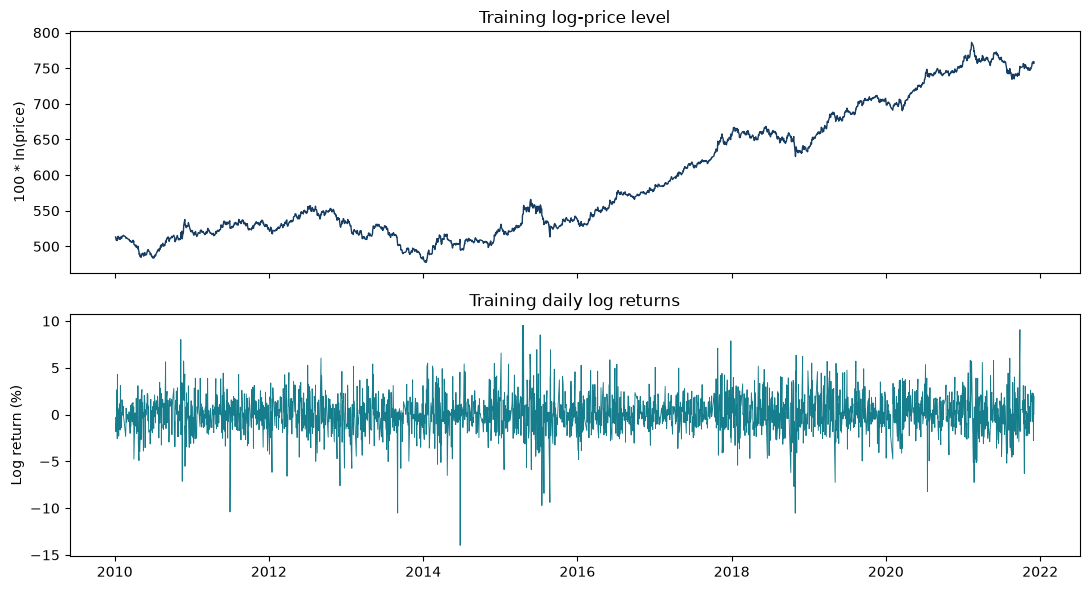

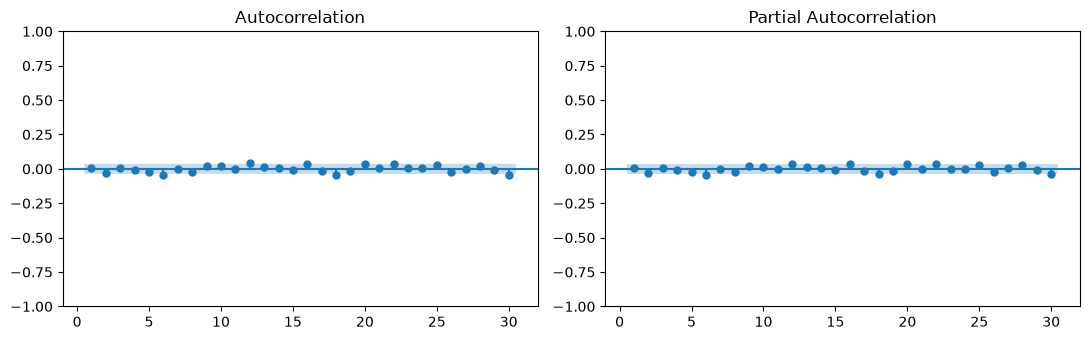

In [2]:
def stationarity_analysis(train, z_train):
    assert len(train) >= 500 and train.index.is_monotonic_increasing
    levels = z_train.loc[train.index]
    print(f'Training interval: {train.index[0].date()} to {train.index[-1].date()}; N={len(train)}')
    rows = []
    for name, series in [('100*log(price)', levels), ('Log return (%)', train)]:
        a = adfuller(series, regression='c', autolag='AIC')
        rows.append({'Series': name, 'Deterministic': 'c', 'ADF': a[0], 'p_value': a[1], 'ADF_lags': a[2], 'Effective_N': a[3]})
    table = pd.DataFrame(rows).set_index('Series')
    save_table(table, 'q1_adf')
    fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
    axes[0].plot(levels.index, levels, lw=1, color='#163c61')
    axes[0].set(title='Training log-price level', ylabel='100 * ln(price)')
    axes[1].plot(train.index, train, lw=0.65, color='#167d8d')
    axes[1].set(title='Training daily log returns', ylabel='Log return (%)')
    save_figure(fig, 'q1_training_series')
    fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
    plot_acf(train, lags=30, zero=False, ax=axes[0])
    plot_pacf(train, lags=30, zero=False, method='ywm', ax=axes[1])
    save_figure(fig, 'q1_return_correlograms')
    return table
stationarity_analysis(train, z_train);

## Training-only model comparison

AR(2), MA(2), and ARMA(2,1) share the same sample and constant specification. The comparison rule is minimum BIC, fixed before holdout evaluation. All estimates must converge. In this parameterization, const is the long-run return location, and MA terms multiply lagged innovations.

In [3]:
def compare_models(train):
    fits, table, selected = candidates(train)
    save_table(table, 'q2_candidates')
    print('Selection criterion fixed before holdout evaluation: BIC')
    print('Selected:', selected)
    save_table(fits[selected].params.to_frame('Estimate'), 'q2_selected_parameters')
    return (table, selected)
compare_models(train);

,Order,AIC,BIC,Converged,param_const,param_ar.L1,param_ar.L2,param_sigma2,param_ma.L1,param_ma.L2
Model,,,,,,,,,,
MA(2),"(0, 0, 2)",12250.727733,12274.603780,True,0.084821,NaN,NaN,4.048516,0.004337,-0.031316
AR(2),"(2, 0, 0)",12250.778193,12274.654240,True,0.084820,0.003947,-0.030774,4.048511,NaN,NaN
"ARMA(2,1)","(2, 0, 1)",12252.617905,12282.462964,True,0.084818,-0.214299,-0.030046,4.048360,0.218518,NaN


Selection criterion fixed before holdout evaluation: BIC
Selected: MA(2)


,Estimate
const,0.084821
ma.L1,0.004337
ma.L2,-0.031316
sigma2,4.048516


## Residual adequacy

The selected mean model is tested at lags 10 and 20. Ljung–Box degrees of freedom subtract p+q, and initialization residuals are excluded. MA(2) does not reject at lag 10 (p=0.163988), but rejects at lag 20 (p=0.027514). Selection by BIC therefore does not imply adequate residual dynamics.

,lb_stat,lb_pvalue
10,11.723191,0.163988
20,31.169573,0.027514


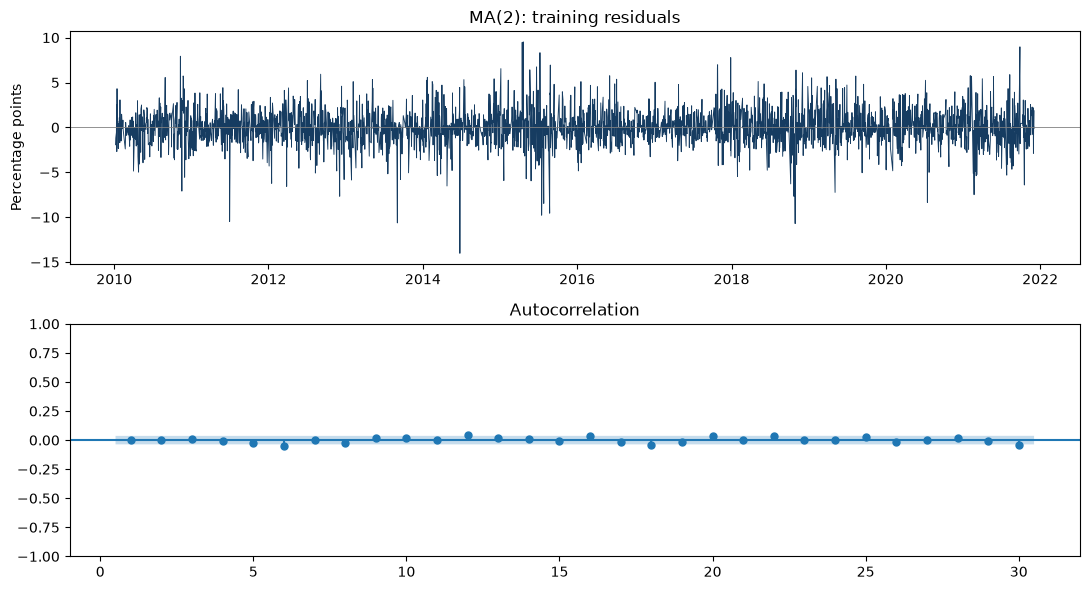

In [4]:
def diagnose_residuals(train):
    fits, _, selected = candidates(train)
    resid, lb = residual_check(train, fits[selected], ORDERS[selected])
    save_table(lb, 'q3_ljung_box')
    fig, axes = plt.subplots(2, 1, figsize=(11, 6))
    axes[0].plot(resid.index, resid, lw=0.65, color='#163c61')
    axes[0].axhline(0, color='gray', lw=0.6)
    axes[0].set(title=f'{selected}: training residuals', ylabel='Percentage points')
    plot_acf(resid, lags=30, zero=False, ax=axes[1])
    save_figure(fig, 'q3_residual_diagnostics')
    return lb
diagnose_residuals(train);

## Fixed-origin return forecasts

The selected model forecasts all 20 returns without updating with observed test values. Zero returns and the training mean are benchmarks. RMSE and MAE are computed on aligned dates in percentage points. MA(2)'s RMSE of 2.218777 is only slightly below zero returns (2.225323) and the training mean (2.219527). Prediction bands are model-based Gaussian intervals.

,MAE,RMSE
MA(2),1.713472,2.218777
Zero return,1.724269,2.225323
Training mean,1.715787,2.219527


,MA(2),Zero return,Training mean,Actual
Time,,,,
2021-12-06,0.096751,0.0,0.08482,-0.232536
2021-12-07,0.026608,0.0,0.08482,-0.582694
2021-12-08,0.084821,0.0,0.08482,4.358421
2021-12-09,0.084821,0.0,0.08482,2.109267
2021-12-10,0.084821,0.0,0.08482,0.165208
2021-12-13,0.084821,0.0,0.08482,1.340261
2021-12-14,0.084821,0.0,0.08482,1.490117
2021-12-15,0.084821,0.0,0.08482,-0.700120
2021-12-16,0.084821,0.0,0.08482,-0.752709


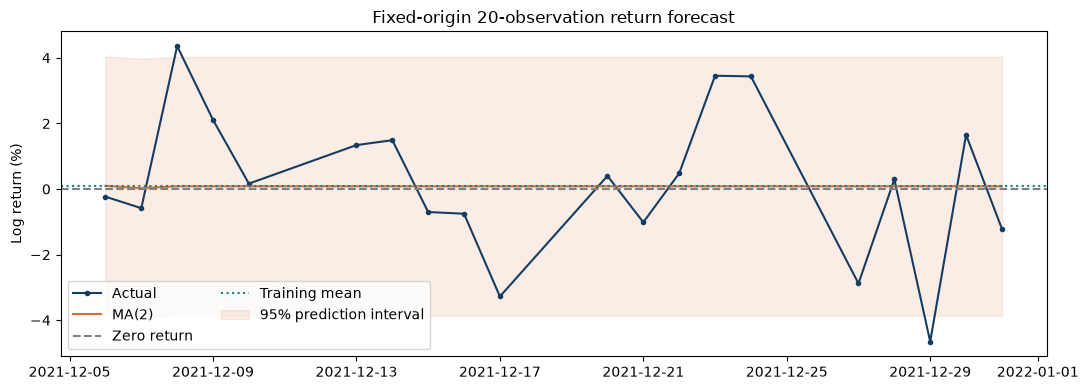

In [5]:
def evaluate_returns(train, test, H):
    fits, _, selected = candidates(train)
    prediction = fits[selected].get_forecast(steps=H)
    forecasts = pd.DataFrame({selected: np.asarray(prediction.predicted_mean), 'Zero return': 0.0, 'Training mean': float(train.mean())}, index=test.index)
    table = metrics(forecasts, test)
    save_table(table, 'q4_return_metrics')
    save_table(forecasts.assign(Actual=test), 'q4_return_forecasts')
    band = np.asarray(prediction.conf_int())
    fig, ax = plt.subplots(figsize=(11, 4))
    ax.plot(test.index, test, 'o-', ms=3, label='Actual', color='#163c61')
    ax.plot(test.index, forecasts[selected], label=selected, color='#d56d36')
    ax.axhline(0, ls='--', color='gray', label='Zero return')
    ax.axhline(train.mean(), ls=':', color='#167d8d', label='Training mean')
    ax.fill_between(test.index, band[:, 0], band[:, 1], alpha=0.12, color='#d56d36', label='95% prediction interval')
    ax.set(title='Fixed-origin 20-observation return forecast', ylabel='Log return (%)')
    ax.legend(ncol=2)
    save_figure(fig, 'q4_return_forecast')
    gain = 100 * (1 - table.loc[selected, 'RMSE'] / table.loc['Zero return', 'RMSE'])
    return table
evaluate_returns(train, test, H);

## Integrated log-price forecasts and nonlinear transformation

ARIMA(1,1,1) is fitted directly to undifferenced z, with no drift and with a linear trend in levels. Both settings are reported, rather than selecting one by holdout performance. The last observed z is the benchmark. Under conditional Gaussian errors, exp(forecast z/100) is a price median; the mean requires exp(forecast variance/20000). Monotone transformation of interval endpoints gives asymmetric price bands. These plug-in intervals do not fully include parameter uncertainty.

,MAE_z,RMSE_z
"ARIMA(1,1,1), no drift",5.395387,5.983584
"ARIMA(1,1,1), drift",4.531076,5.147919
Last value,5.429544,6.021481


,n,t
ar.L1,-0.762065,-0.765393
ma.L1,0.779578,0.782421
sigma2,4.056733,4.049646
x1,NaN,0.084850


,Actual,Median_drift,Gaussian_mean_drift,Lower95,Upper95
Time,,,,,
2021-12-06,1967.30,1974.985180,1975.385120,1898.604424,2054.438729
2021-12-07,1955.87,1975.565099,1976.379039,1867.495922,2089.888076
2021-12-08,2043.00,1978.082026,1979.300944,1846.573925,2118.955785
2021-12-09,2086.55,1979.117658,1980.749523,1827.731399,2143.042848
2021-12-10,2090.00,1981.290555,1983.330863,1812.710356,2165.548538
2021-12-13,2118.20,1982.594783,1985.048180,1798.460348,2185.581728
2021-12-14,2150.00,1984.566974,1987.431414,1786.276763,2204.868895
2021-12-15,2135.00,1986.030002,1989.308327,1774.589460,2222.663470
2021-12-16,2118.99,1987.885596,1991.577094,1764.172524,2239.967513


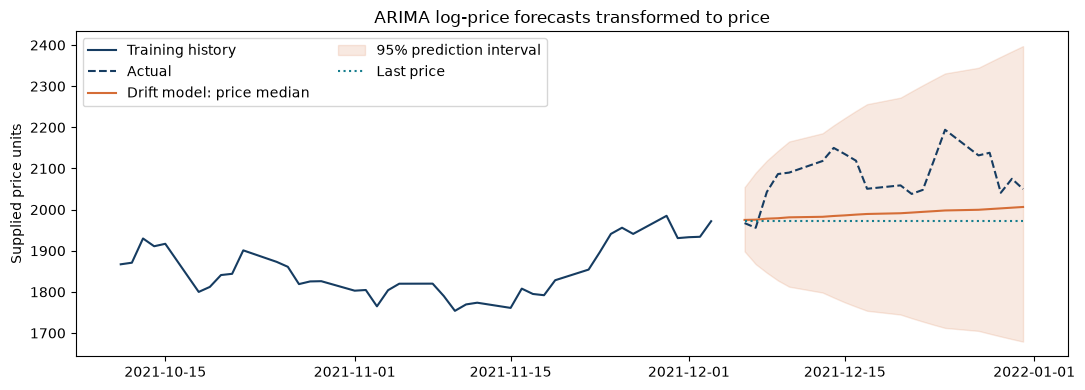

In [6]:
def evaluate_log_prices(z_train, z_test, data, H):
    fits = {trend: fit_model(z_train, (1, 1, 1), trend) for trend in ('n', 't')}
    preds = {trend: fit.get_forecast(steps=H) for trend, fit in fits.items()}
    forecasts = pd.DataFrame({'ARIMA(1,1,1), no drift': np.asarray(preds['n'].predicted_mean), 'ARIMA(1,1,1), drift': np.asarray(preds['t'].predicted_mean), 'Last value': float(z_train.iloc[-1])}, index=z_test.index)
    table = metrics(forecasts, z_test).rename(columns={'MAE': 'MAE_z', 'RMSE': 'RMSE_z'})
    save_table(table, 'q5_log_price_metrics')
    save_table(pd.DataFrame({t: f.params for t, f in fits.items()}), 'q5_parameters')
    band_z = np.asarray(preds['t'].conf_int())
    med = np.exp(forecasts.iloc[:, 1] / 100)
    band = np.exp(band_z / 100)
    mean = np.exp(forecasts.iloc[:, 1] / 100 + np.asarray(preds['t'].var_pred_mean) / 20000)
    save_table(pd.DataFrame({'Actual': data.loc[z_test.index, 'close'], 'Median_drift': med, 'Gaussian_mean_drift': mean, 'Lower95': band[:, 0], 'Upper95': band[:, 1]}, index=z_test.index), 'q5_price_forecasts')
    fig, ax = plt.subplots(figsize=(11, 4))
    history = data.loc[:z_train.index[-1], 'close'].iloc[-40:]
    ax.plot(history.index, history, color='#163c61', label='Training history')
    ax.plot(z_test.index, data.loc[z_test.index, 'close'], color='#163c61', ls='--', label='Actual')
    ax.plot(z_test.index, med, color='#d56d36', label='Drift model: price median')
    ax.fill_between(z_test.index, band[:, 0], band[:, 1], color='#d56d36', alpha=0.15, label='95% prediction interval')
    ax.hlines(history.iloc[-1], z_test.index[0], z_test.index[-1], color='#167d8d', ls=':', label='Last price')
    ax.set(title='ARIMA log-price forecasts transformed to price', ylabel='Supplied price units')
    ax.legend(ncol=2)
    save_figure(fig, 'q5_price_forecast')
    return table
evaluate_log_prices(z_train, z_test, data, H);

## Selection sensitivity and volatility diagnostics

Earlier 60% and 80% training prefixes assess whether the BIC choice depends on the estimation period. BIC values from different sample sizes are not ranked against one another. The ARCH-LM result provides evidence against constant conditional variance (p approximately 4.04e-09); it does not identify a uniquely suitable volatility model.

In [7]:
fits, comparison, selected = candidates(train)
resid, lb = residual_check(train, fits[selected], ORDERS[selected])
arch = het_arch(resid, nlags=10, ddof=sum(ORDERS[selected]))
stability = []
for fraction in (.6, .8, 1.):
    prefix = train.iloc[:int(len(train) * fraction)]
    _, table, choice = candidates(prefix)
    stability.append({"Training_fraction": fraction, "N": len(prefix),
                      "End": str(prefix.index[-1].date()), "BIC_choice": choice,
                      "BIC": float(table.loc[choice, "BIC"])})
save_table(pd.DataFrame(stability), "training_selection_stability")
save_table(pd.DataFrame([{"ARCH_LM": arch[0], "p_value": arch[1], "Lags": 10}]),
           "arch_diagnostic")
rmetrics = pd.read_csv(OUT / "q4_return_metrics.csv", index_col=0)
pmetrics = pd.read_csv(OUT / "q5_log_price_metrics.csv", index_col=0)
summary = {
    "n_prices": len(data), "n_train_returns": len(train), "n_holdout": H,
    "start": str(data.index[0].date()), "end": str(data.index[-1].date()),
    "train_end": str(train.index[-1].date()), "test_start": str(test.index[0].date()),
    "selected": selected, "selected_bic": float(comparison.loc[selected, "BIC"]),
    "lb_p10": float(lb.iloc[0].lb_pvalue), "lb_p20": float(lb.iloc[1].lb_pvalue),
    "arch_p": float(arch[1]), "return_metrics": rmetrics.to_dict(orient="index"),
    "price_metrics": pmetrics.to_dict(orient="index")}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
assert selected == "MA(2)" and lb.iloc[1].lb_pvalue < .05
assert len(data) == len(train) + H + 1
assert not train.index.intersection(test.index).size
predictions = pd.read_csv(OUT / "q4_return_forecasts.csv", index_col=0, parse_dates=True)
assert predictions.index.equals(test.index)
assert np.allclose(predictions.Actual, test)
recomputed = metrics(predictions.drop(columns="Actual"), test)
assert np.allclose(recomputed, rmetrics)
price_predictions = pd.read_csv(OUT / "q5_price_forecasts.csv", index_col=0)
assert (price_predictions.Lower95 <= price_predictions.Median_drift).all()
assert (price_predictions.Median_drift <= price_predictions.Upper95).all()
assert (price_predictions.Gaussian_mean_drift >= price_predictions.Median_drift).all()
print("Verified: sample accounting, sealed holdout, forecast metrics and transformed intervals.")

,Training_fraction,N,End,BIC_choice,BIC
0,0.6,1734,2017-03-07,MA(2),7338.156258
1,0.8,2312,2019-07-18,MA(2),9820.927299
2,1.0,2890,2021-12-03,MA(2),12274.603780


,ARCH_LM,p_value,Lags
0,59.751585,4.038460e-09,10


Verified: sample accounting, sealed holdout, forecast metrics and transformed intervals.


## Conclusion

MA(2) is the BIC winner among the three specified candidates, but residual dependence and ARCH effects limit its adequacy. Its 0.294% RMSE improvement over zero returns is descriptive evidence from one short window. Drift improves this log-price comparison (RMSE_z 5.147919 versus 6.021481 for the last value), without establishing general forecast superiority. Repeated forecast origins and volatility modelling would be useful extensions; neither a profitable strategy nor an independently collected dataset is claimed.

## Methods and provenance

This analysis develops supplied econometrics coursework and retains its original datasets and teaching notebook in source_materials. AI assistance was used for code completion, analytical organization, verification, and English writing. The data were supplied with the course; upstream vendor and price-adjustment details were not independently established.

Methods follow the statsmodels ARIMA, ADF, Ljung–Box and ARCH-LM APIs. The accompanying report records their documentation links.